In [1]:
import os
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, auc, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
os.makedirs("graphs", exist_ok=True)


def save_show(filename):
    """Save the current graph into graphs/ and display it."""
    plt.tight_layout()
    plt.savefig(f"graphs/{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
if not os.path.exists("data.csv"):
    try:
        from google.colab import files
        print("data.csv not found. Please choose the file to upload...")
        uploaded = files.upload()
        csv_name = list(uploaded.keys())[0]
        os.rename(csv_name, "data.csv")
    except ImportError:
        raise FileNotFoundError("data.csv not found. Put it in the same folder as this notebook.")

In [3]:
df = pd.read_csv("data.csv")
print("Shape:", df.shape)

Shape: (569, 33)


In [4]:
print(df.head(5))

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [5]:
print("\n--- Info ---")
df.info()


--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se

In [6]:
df.columns = df.columns.str.strip().str.lower()

drop_cols = [c for c in df.columns if c == "id" or c.startswith("unnamed")]
df = df.drop(columns=drop_cols)

target_col = next((c for c in ["diagnosis", "target", "class", "label"] if c in df.columns), None)
if target_col is None:
    raise ValueError(f"No target column found. Your columns are: {list(df.columns)}")
if target_col != "diagnosis":
    df = df.rename(columns={target_col: "diagnosis"})

if df["diagnosis"].dtype == object or str(df["diagnosis"].dtype) in ("str", "string", "category"):
    df["diagnosis"] = (df["diagnosis"].astype(str).str.strip().str.upper().str[0]
                       .map({"M": 1, "B": 0}))

df = df.dropna(axis=1, how="all").dropna(subset=["diagnosis"])
df["diagnosis"] = df["diagnosis"].astype(int)

print("Shape after cleaning:", df.shape)

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape after cleaning: (569, 31)
Missing values: 0
Duplicate rows: 0



Class counts (1 = Malignant, 0 = Benign):
 diagnosis
0    357
1    212
Name: count, dtype: int64

--- Statistical summary ---
                         count        mean         std         min  \
diagnosis                569.0    0.372583    0.483918    0.000000   
radius_mean              569.0   14.127292    3.524049    6.981000   
texture_mean             569.0   19.289649    4.301036    9.710000   
perimeter_mean           569.0   91.969033   24.298981   43.790000   
area_mean                569.0  654.889104  351.914129  143.500000   
smoothness_mean          569.0    0.096360    0.014064    0.052630   
compactness_mean         569.0    0.104341    0.052813    0.019380   
concavity_mean           569.0    0.088799    0.079720    0.000000   
concave points_mean      569.0    0.048919    0.038803    0.000000   
symmetry_mean            569.0    0.181162    0.027414    0.106000   
fractal_dimension_mean   569.0    0.062798    0.007060    0.049960   
radius_se                569.0   

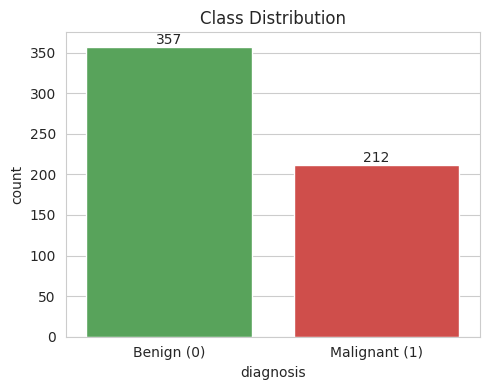

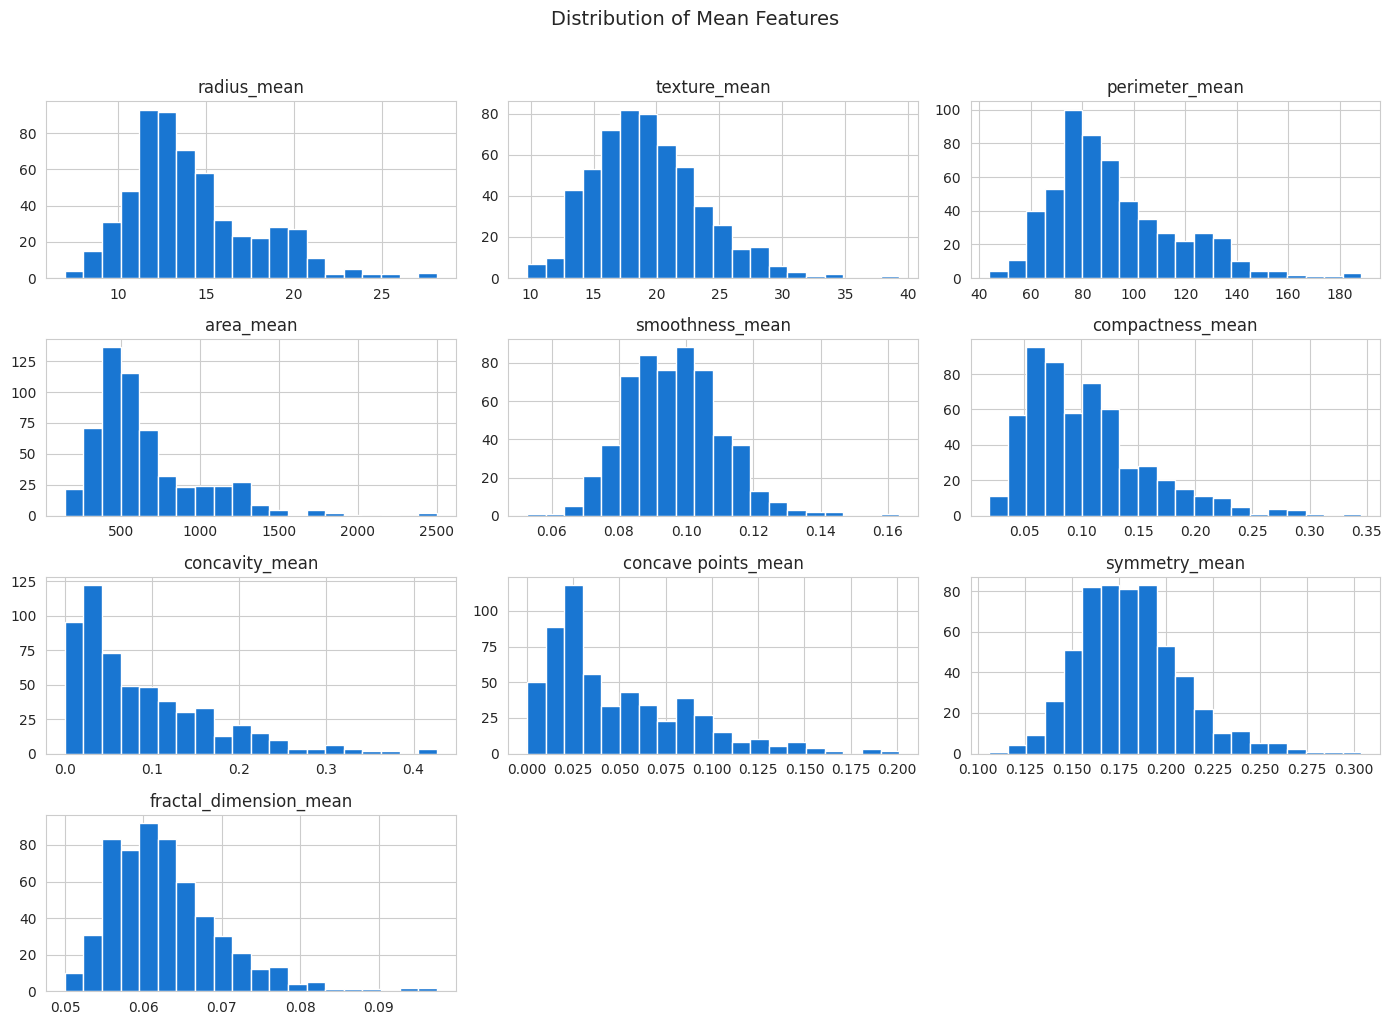

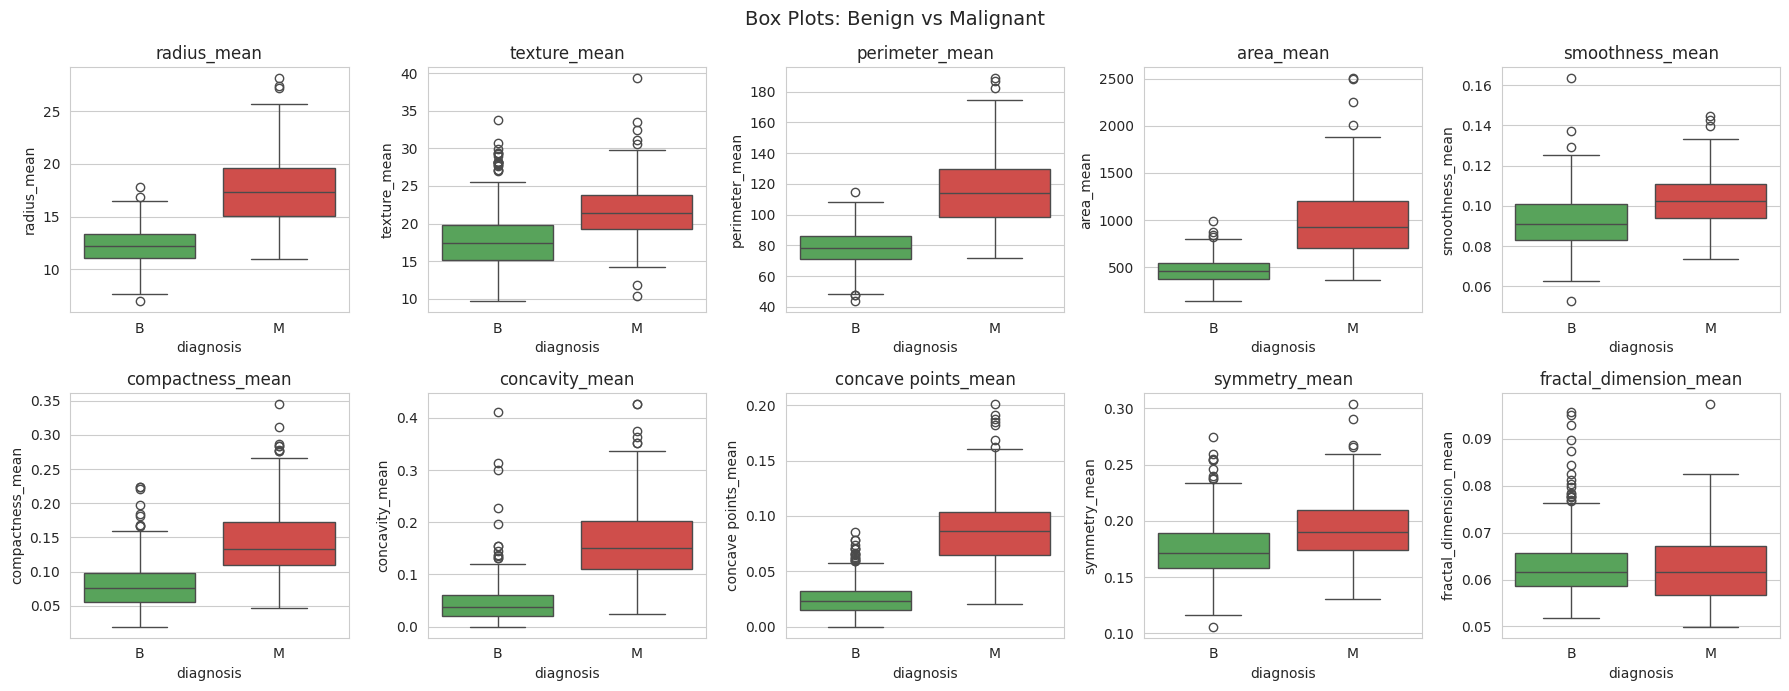

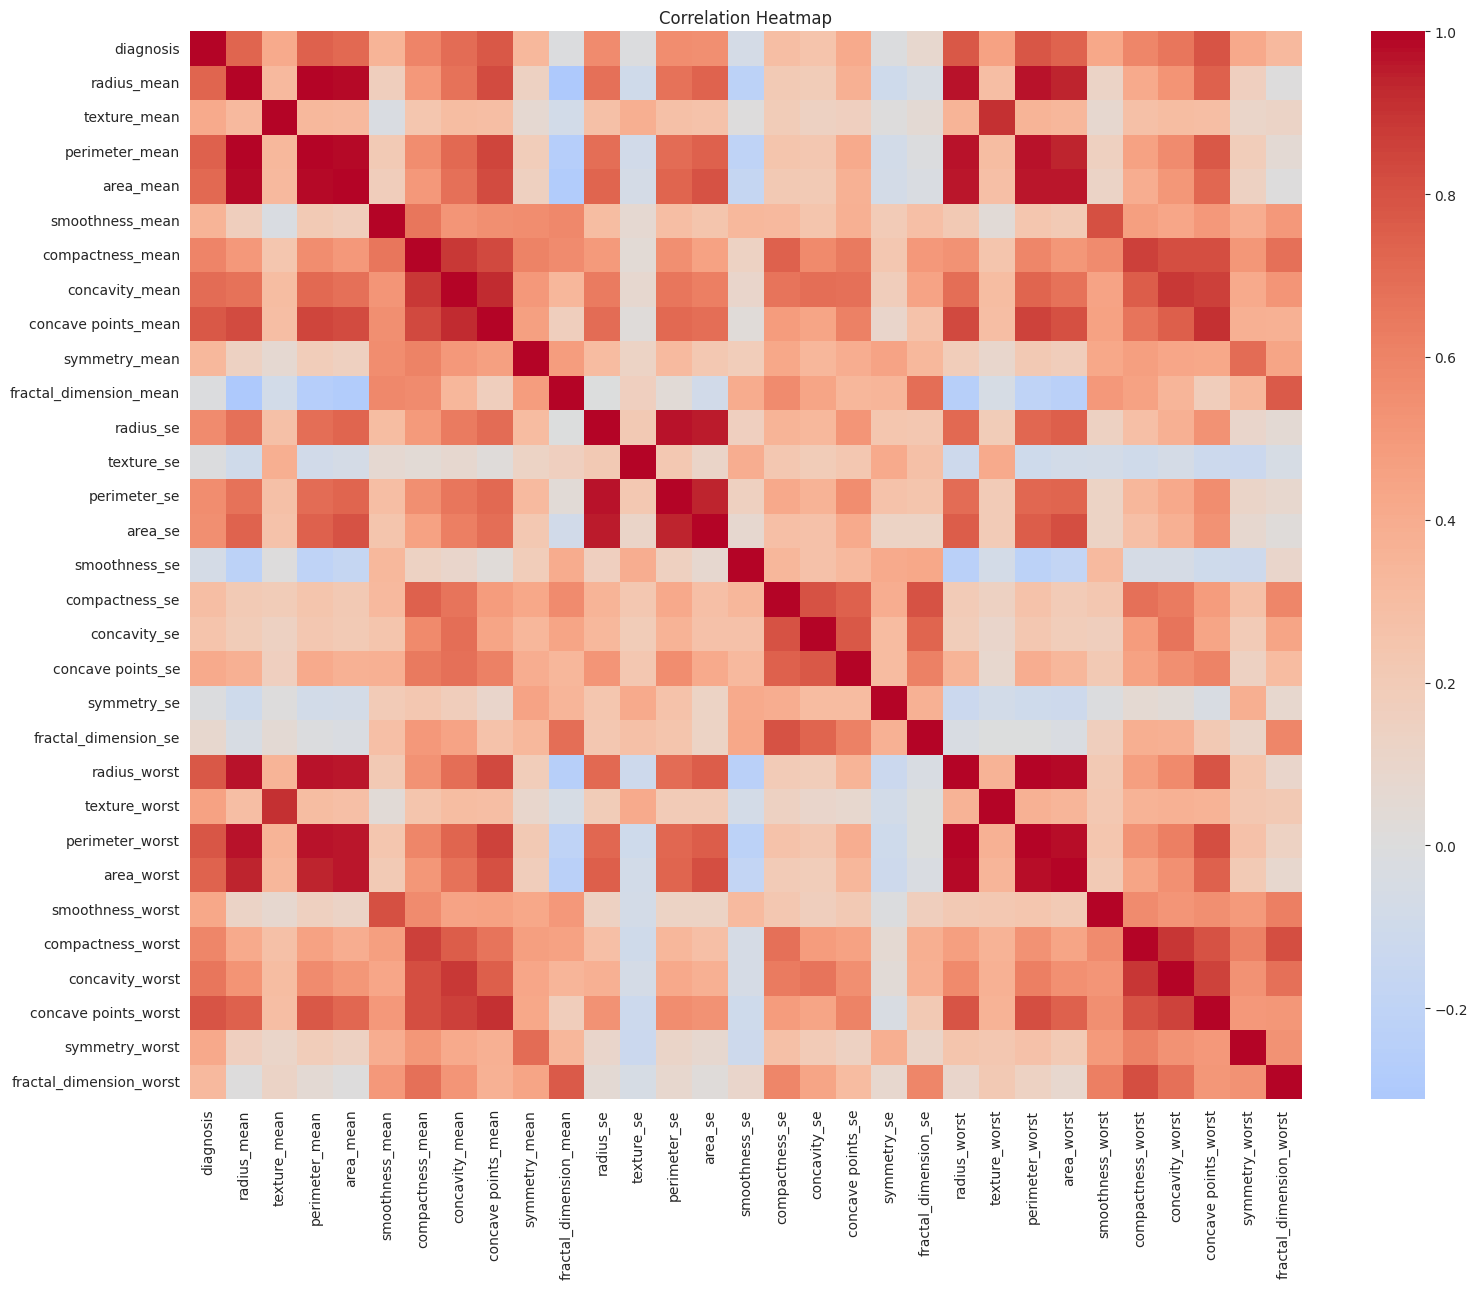

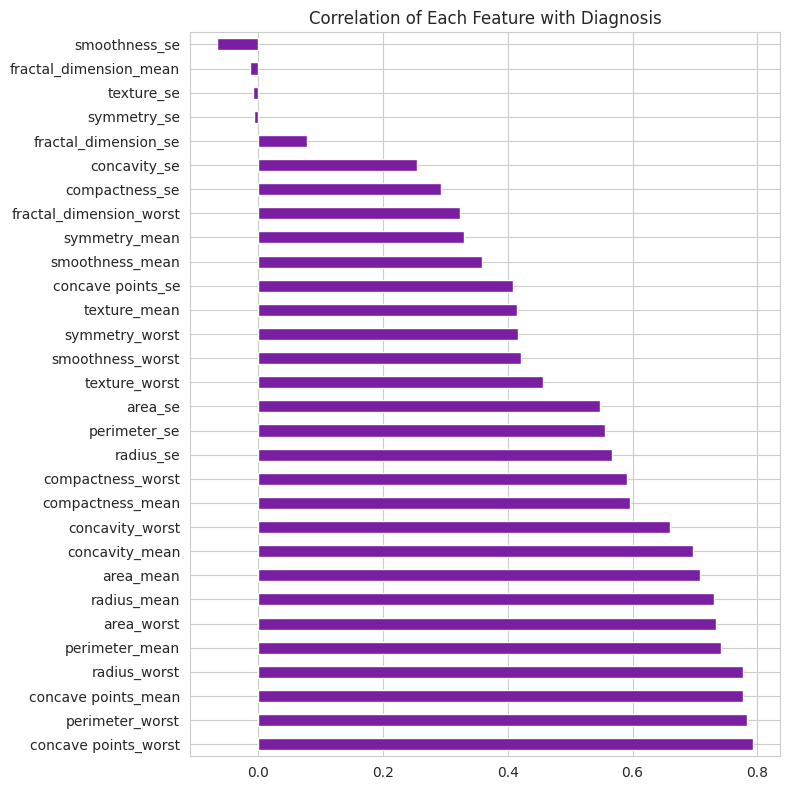


Top 5 correlated features:
 concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
Name: diagnosis, dtype: float64


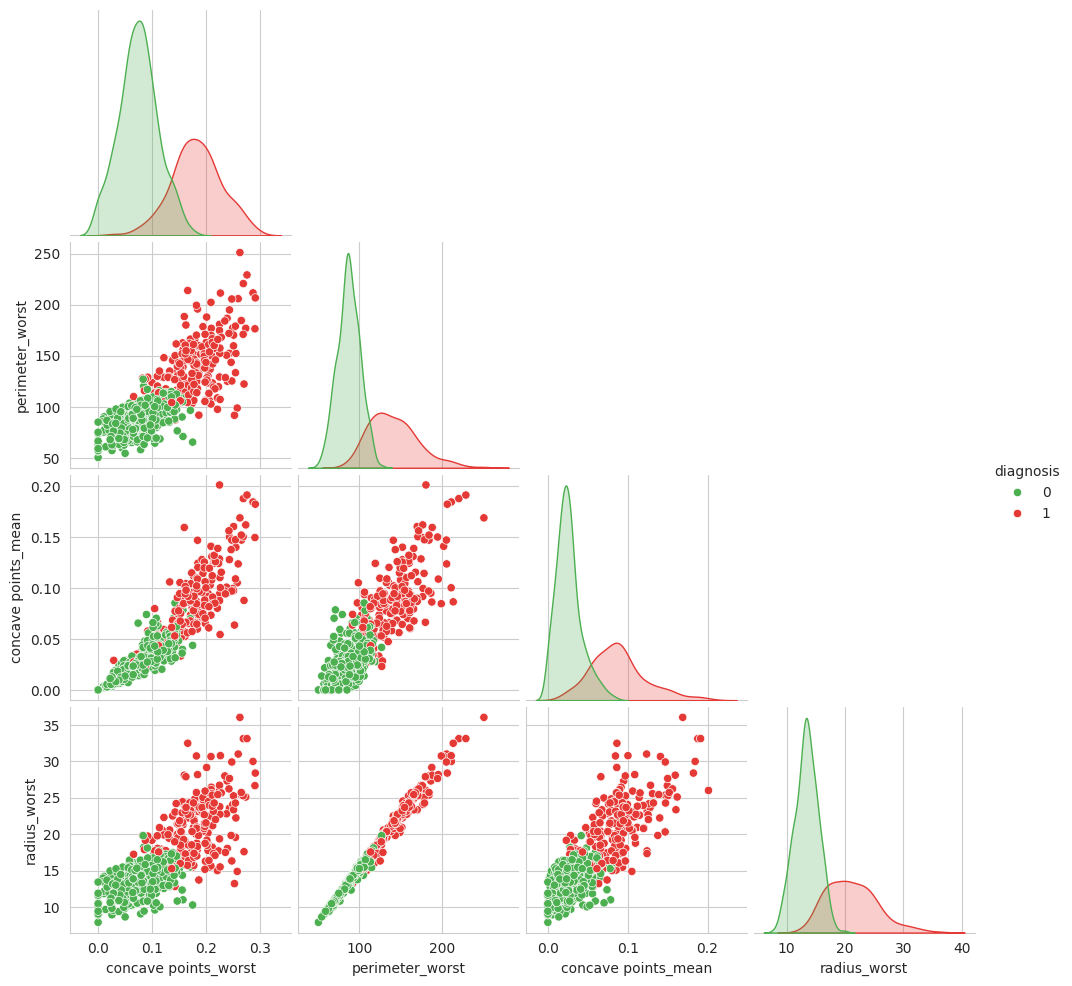

In [8]:
#EDA
print("\nClass counts (1 = Malignant, 0 = Benign):\n", df["diagnosis"].value_counts())
print("\n--- Statistical summary ---")
print(df.describe().T)

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="diagnosis", hue="diagnosis", data=df,
                   palette=["#4CAF50", "#E53935"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign (0)", "Malignant (1)"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Class Distribution")
save_show("01_class_distribution")

mean_cols = [c for c in df.columns if "mean" in c][:10]
if len(mean_cols) < 10:                      # fallback if column names are different
    mean_cols = [c for c in df.columns if c != "diagnosis"][:10]
df[mean_cols].hist(bins=20, figsize=(14, 10), color="#1976D2", edgecolor="white")
plt.suptitle("Distribution of Mean Features", y=1.02, fontsize=14)
save_show("02_histograms")

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.boxplot(x="diagnosis", y=col, hue="diagnosis", data=df,
                palette=["#4CAF50", "#E53935"], legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["B", "M"])
    ax.set_title(col)
plt.suptitle("Box Plots: Benign vs Malignant", fontsize=14)
save_show("03_boxplots")

plt.figure(figsize=(16, 13))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
save_show("04_correlation_heatmap")

corr_target = df.corr()["diagnosis"].drop("diagnosis").sort_values(ascending=False)
plt.figure(figsize=(8, 8))
corr_target.plot(kind="barh", color="#7B1FA2")
plt.title("Correlation of Each Feature with Diagnosis")
save_show("05_target_correlation")
print("\nTop 5 correlated features:\n", corr_target.head(5))

top4 = corr_target.abs().sort_values(ascending=False).index[:4].tolist()
sns.pairplot(df[top4 + ["diagnosis"]], hue="diagnosis",
             palette=["#4CAF50", "#E53935"], corner=True)
plt.savefig("graphs/06_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

Train size: (455, 30) | Test size: (114, 30)


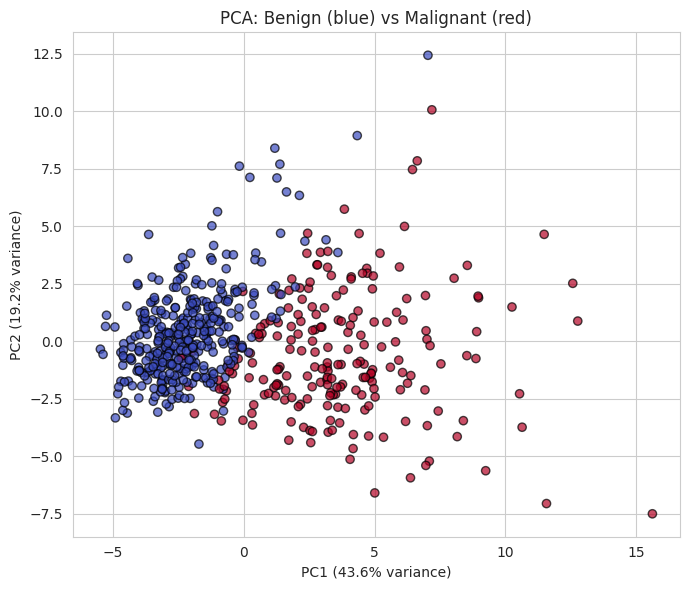

In [10]:
#  TRAIN/TEST SPLIT AND SCALING
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaler.transform(X))
plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA: Benign (blue) vs Malignant (red)")
save_show("07_pca")

Original features        : 30
After correlation filter : 20  (dropped 10: ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst'])


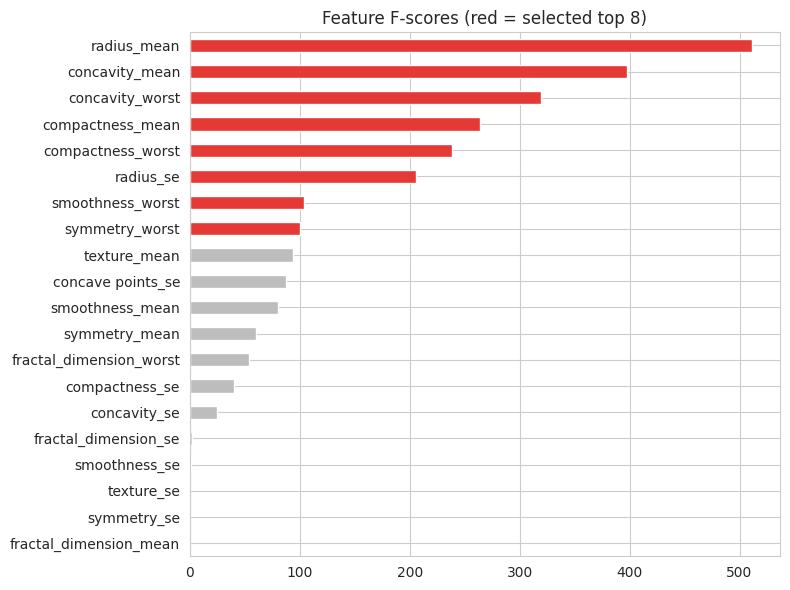


Final selected features (8): ['radius_mean', 'compactness_mean', 'concavity_mean', 'radius_se', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'symmetry_worst']
Train shape now: (455, 8) | Test shape now: (114, 8)


In [11]:
#FEATURE SELECTION
CORR_THRESHOLD = 0.90
TOP_K = 8
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if (upper[c] > CORR_THRESHOLD).any()]
kept = [c for c in X_train.columns if c not in to_drop]
print(f"Original features        : {X_train.shape[1]}")
print(f"After correlation filter : {len(kept)}  (dropped {len(to_drop)}: {to_drop})")


if TOP_K is not None and TOP_K < len(kept):
    skb = SelectKBest(score_func=f_classif, k=TOP_K).fit(X_train[kept], y_train)
    selected_features = [str(f) for f in np.array(kept)[skb.get_support()]]
    f_scores = pd.Series(skb.scores_, index=kept).sort_values(ascending=False)
    plt.figure(figsize=(8, 6))
    colors = ["#E53935" if f in selected_features else "#BDBDBD" for f in f_scores.index]
    f_scores[::-1].plot(kind="barh", color=colors[::-1])
    plt.title(f"Feature F-scores (red = selected top {TOP_K})")
    save_show("07b_feature_selection")
else:
    selected_features = kept

print(f"\nFinal selected features ({len(selected_features)}):", selected_features)


selected_idx = [list(X.columns).index(f) for f in selected_features]
X_train_s_all, X_test_s_all = X_train_s, X_test_s
X_train_s = X_train_s_all[:, selected_idx]
X_test_s = X_test_s_all[:, selected_idx]
print("Train shape now:", X_train_s.shape, "| Test shape now:", X_test_s.shape)

In [15]:
models = {

    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),

    "AdaBoost": AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                                    max_depth=3, random_state=42),
}

In [26]:
def evaluate(models_dict, title_suffix=""):
    """Train, evaluate and plot confusion matrices + ROC for all models."""
    rows = {}
    n = len(models_dict)
    ncols = 4 if n > 6 else 3
    nrows = math.ceil(n / ncols)
    fig_cm, axes_cm = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4 * nrows))
    axes_flat = np.atleast_1d(axes_cm).ravel()
    plt.figure(figsize=(8, 7))
    roc_ax = plt.gca()

    for ax, (name, model) in zip(axes_flat, models_dict.items()):
        model.fit(X_train_s, y_train)
        pred = model.predict(X_test_s)
        prob = model.predict_proba(X_test_s)[:, 1]

        fpr, tpr, _ = roc_curve(y_test, prob)
        rows[name] = {
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1-Score": f1_score(y_test, pred),
            "AUC": auc(fpr, tpr),
        }

        sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Benign", "Malignant"],
                    yticklabels=["Benign", "Malignant"], ax=ax, cbar=False)
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        roc_ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

        print(f"\n===== {name} {title_suffix} =====")
        print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))

    for ax in axes_flat[n:]:
        ax.axis("off")

    tag = title_suffix.strip("()").replace(" ", "_") or "base"
    fig_cm.suptitle(f"Confusion Matrices {title_suffix}", fontsize=14)
    fig_cm.tight_layout()
    fig_cm.savefig(f"graphs/confusion_matrices_{tag}.png", dpi=150, bbox_inches="tight")
    plt.figure(fig_cm.number)
    plt.show()

    roc_ax.plot([0, 1], [0, 1], "k--")
    roc_ax.set_xlabel("False Positive Rate")
    roc_ax.set_ylabel("True Positive Rate (Recall)")
    roc_ax.set_title(f"ROC Curves {title_suffix}")
    roc_ax.legend(loc="lower right", fontsize=8)
    plt.savefig(f"graphs/roc_curves_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()

    return pd.DataFrame(rows).T


===== Logistic Regression (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.93      0.99      0.96        72
   Malignant       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114


===== KNN (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


===== Decision Tree (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.93      0.96      0.95        72
   Malignant       0.93      0.88      0.90        42

    accuracy                           0.93       114
   macro 

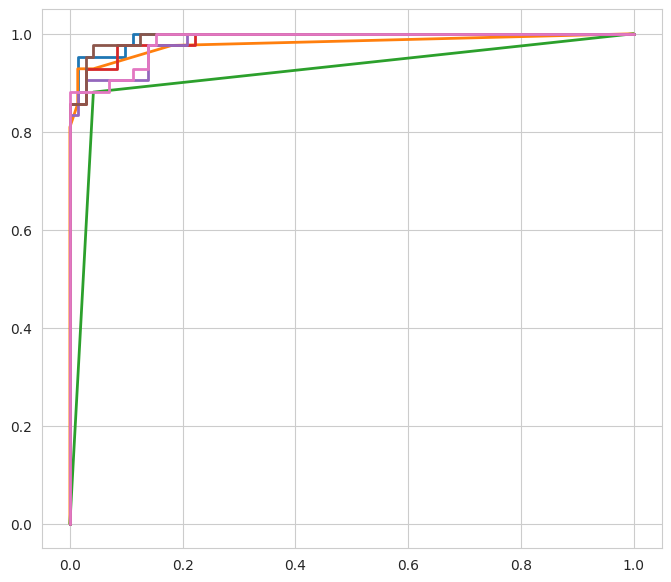

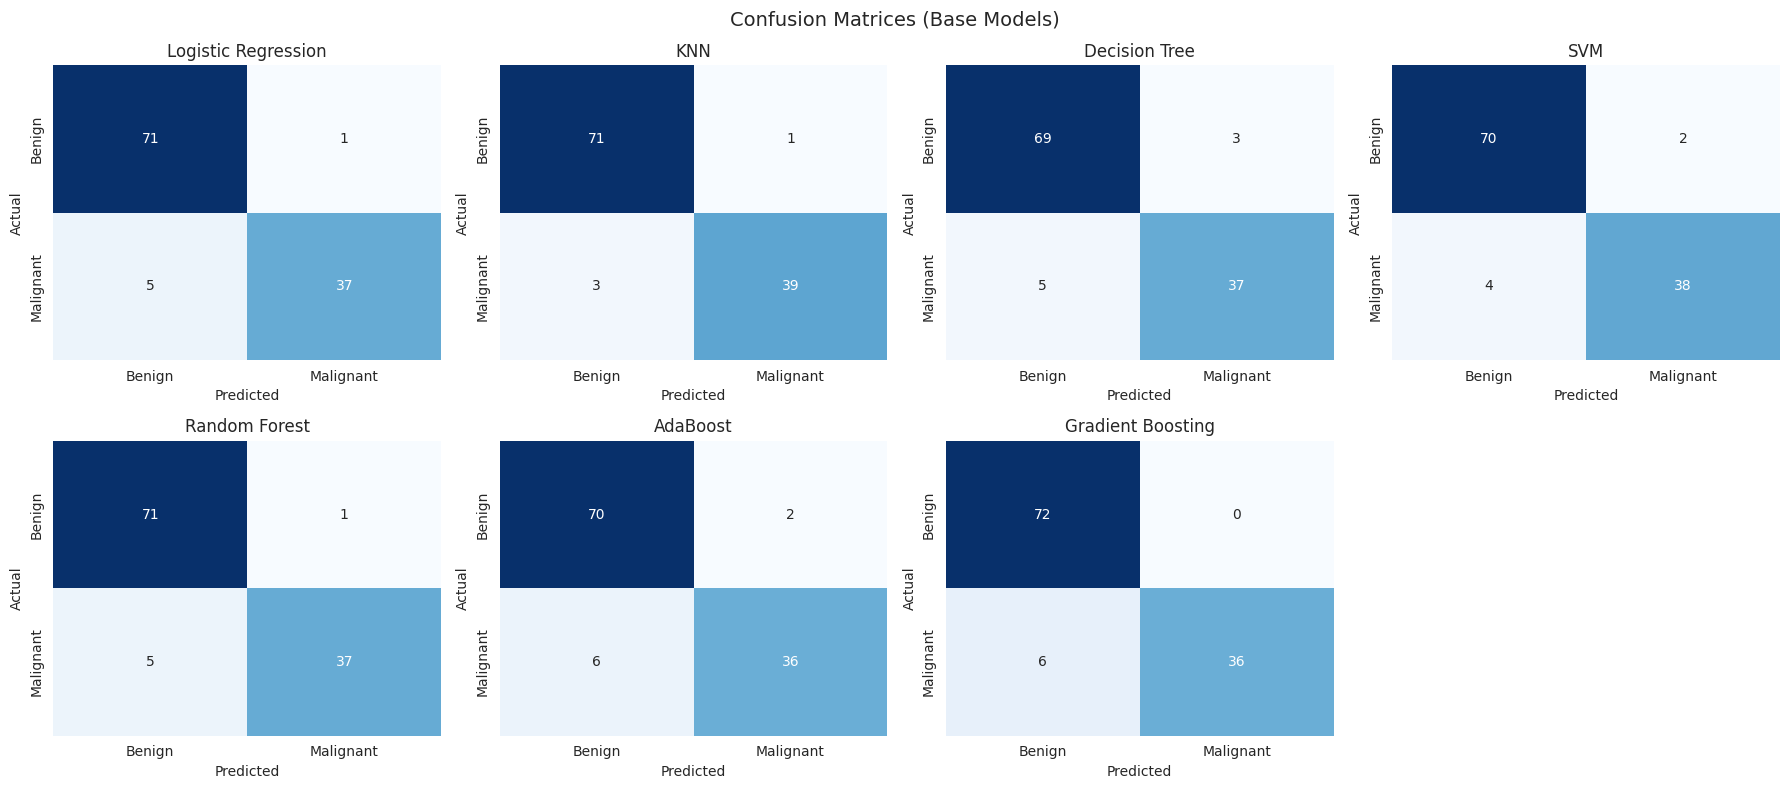

<Figure size 640x480 with 0 Axes>


===== BASE MODEL COMPARISON =====
                     Accuracy  Precision  Recall  F1-Score     AUC
Logistic Regression    0.9474     0.9737  0.8810    0.9250  0.9937
KNN                    0.9649     0.9750  0.9286    0.9512  0.9793
Decision Tree          0.9298     0.9250  0.8810    0.9024  0.9196
SVM                    0.9474     0.9500  0.9048    0.9268  0.9888
Random Forest          0.9474     0.9737  0.8810    0.9250  0.9838
AdaBoost               0.9298     0.9474  0.8571    0.9000  0.9934
Gradient Boosting      0.9474     1.0000  0.8571    0.9231  0.9854


In [27]:
results_base = evaluate(models, "(Base Models)")
print("\n===== BASE MODEL COMPARISON =====")
print(results_base.round(4))

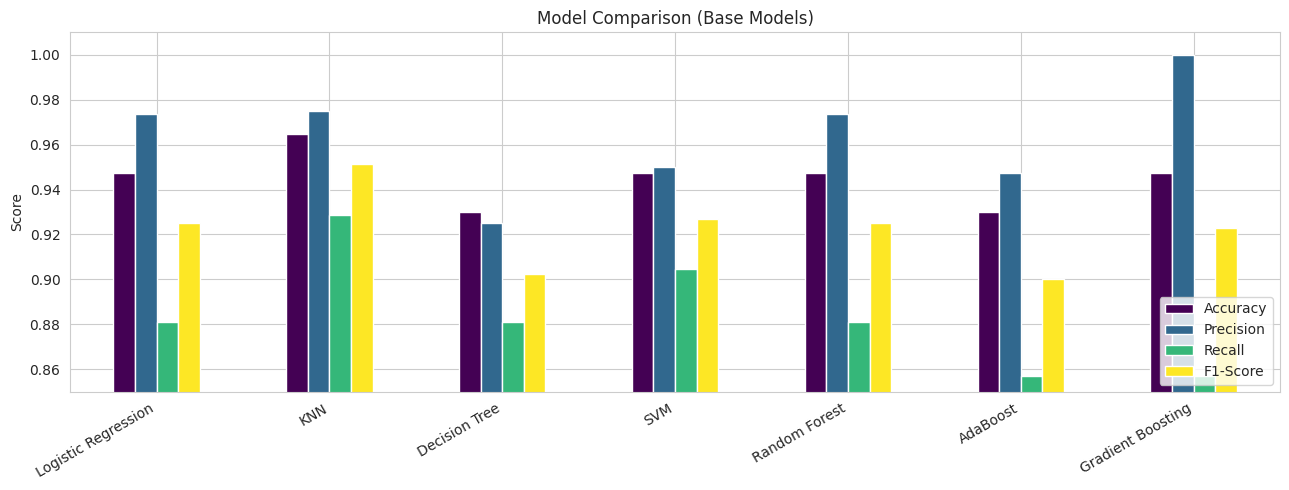

In [28]:
results_base.drop(columns="AUC").plot(kind="bar", figsize=(13, 5), ylim=(0.85, 1.01), colormap="viridis")
plt.title("Model Comparison (Base Models)")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
save_show("10_model_comparison_base")


Logistic Regression: Recall per fold = [0.912 1.    0.882 0.853 0.882] | Mean = 0.9059
KNN: Recall per fold = [0.912 1.    0.794 0.765 0.882] | Mean = 0.8706
Decision Tree: Recall per fold = [0.794 0.971 0.824 0.853 0.912] | Mean = 0.8706
SVM: Recall per fold = [0.882 1.    0.882 0.824 0.912] | Mean = 0.9000
Random Forest: Recall per fold = [0.882 1.    0.794 0.853 0.882] | Mean = 0.8824
AdaBoost: Recall per fold = [0.912 1.    0.853 0.971 0.882] | Mean = 0.9235
Gradient Boosting: Recall per fold = [0.853 1.    0.765 0.912 0.912] | Mean = 0.8882


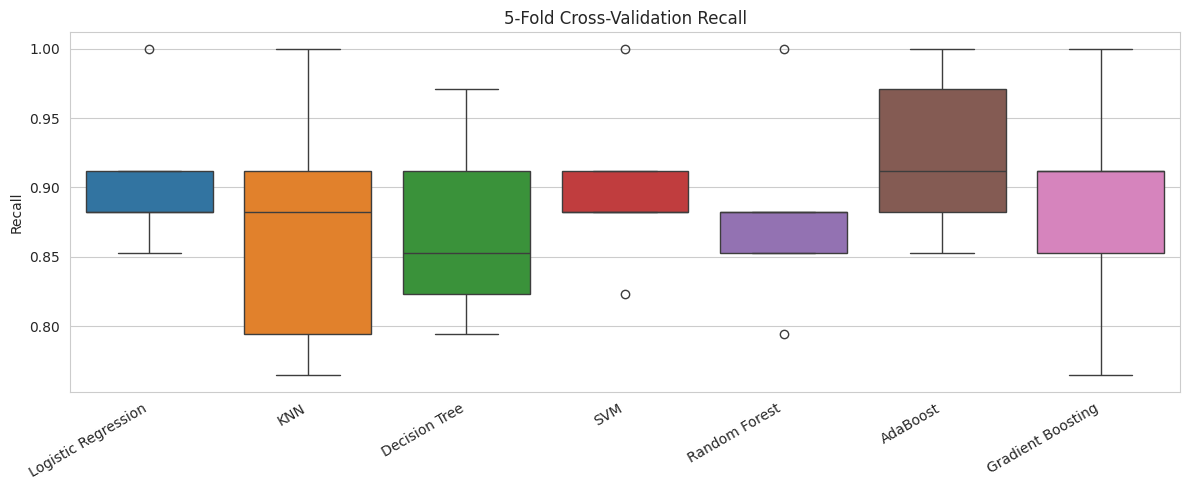

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring="recall")
    cv_scores[name] = scores
    print(f"{name}: Recall per fold = {np.round(scores, 3)} | Mean = {scores.mean():.4f}")

plt.figure(figsize=(12, 5))
sns.boxplot(data=pd.DataFrame(cv_scores))
plt.title("5-Fold Cross-Validation Recall")
plt.ylabel("Recall")
plt.xticks(rotation=30, ha="right")
save_show("11_cross_validation")

In [31]:
param_grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42),
                            {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l2"]}),
    "KNN": (KNeighborsClassifier(),
            {"n_neighbors": [3, 5, 7, 9, 11], "weights": ["uniform", "distance"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
                      {"max_depth": [3, 5, 7, None], "min_samples_split": [2, 5, 10]}),
    "SVM": (SVC(probability=True, random_state=42),
            {"C": [0.1, 1, 10, 100], "kernel": ["linear", "rbf"], "gamma": ["scale", "auto"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"n_estimators": [100, 200, 300], "max_depth": [None, 5, 10],
                       "min_samples_split": [2, 5]}),
    "AdaBoost": (AdaBoostClassifier(random_state=42),
                 {"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.1, 0.5, 1.0]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                          {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1],
                           "max_depth": [2, 3]}),
    }

tuned_models = {}
for name, (model, grid) in param_grids.items():
    gs = GridSearchCV(model, grid, cv=5, scoring="recall", n_jobs=-1)
    gs.fit(X_train_s, y_train)
    tuned_models[name] = gs.best_estimator_
    print(f"{name}\n  Best params: {gs.best_params_}\n  Best CV recall: {gs.best_score_:.4f}")

Logistic Regression
  Best params: {'C': 10, 'penalty': 'l2'}
  Best CV recall: 0.9412
KNN
  Best params: {'n_neighbors': 9, 'weights': 'uniform'}
  Best CV recall: 0.8824
Decision Tree
  Best params: {'max_depth': None, 'min_samples_split': 2}
  Best CV recall: 0.9000
SVM
  Best params: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
  Best CV recall: 0.9412
Random Forest
  Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
  Best CV recall: 0.9000
AdaBoost
  Best params: {'learning_rate': 1.0, 'n_estimators': 200}
  Best CV recall: 0.9176
Gradient Boosting
  Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
  Best CV recall: 0.9176



===== Logistic Regression (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


===== KNN (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.92      0.97      0.95        72
   Malignant       0.95      0.86      0.90        42

    accuracy                           0.93       114
   macro avg       0.93      0.91      0.92       114
weighted avg       0.93      0.93      0.93       114


===== Decision Tree (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.93      0.96      0.95        72
   Malignant       0.93      0.88      0.90        42

    accuracy                           0.93       114
   mac

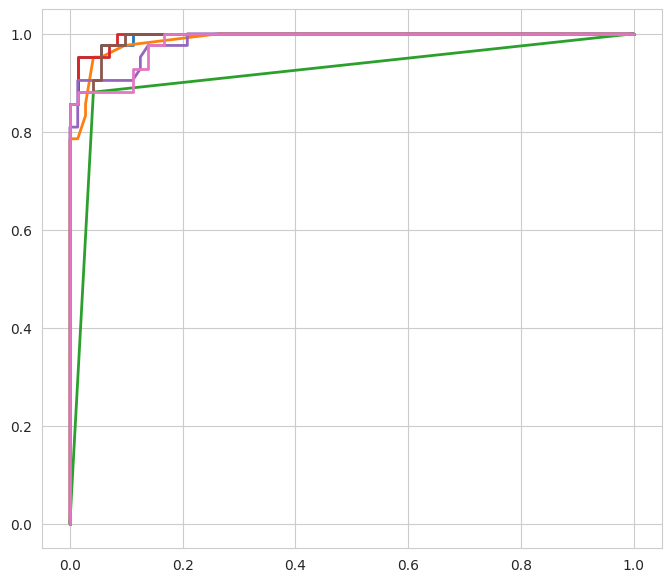

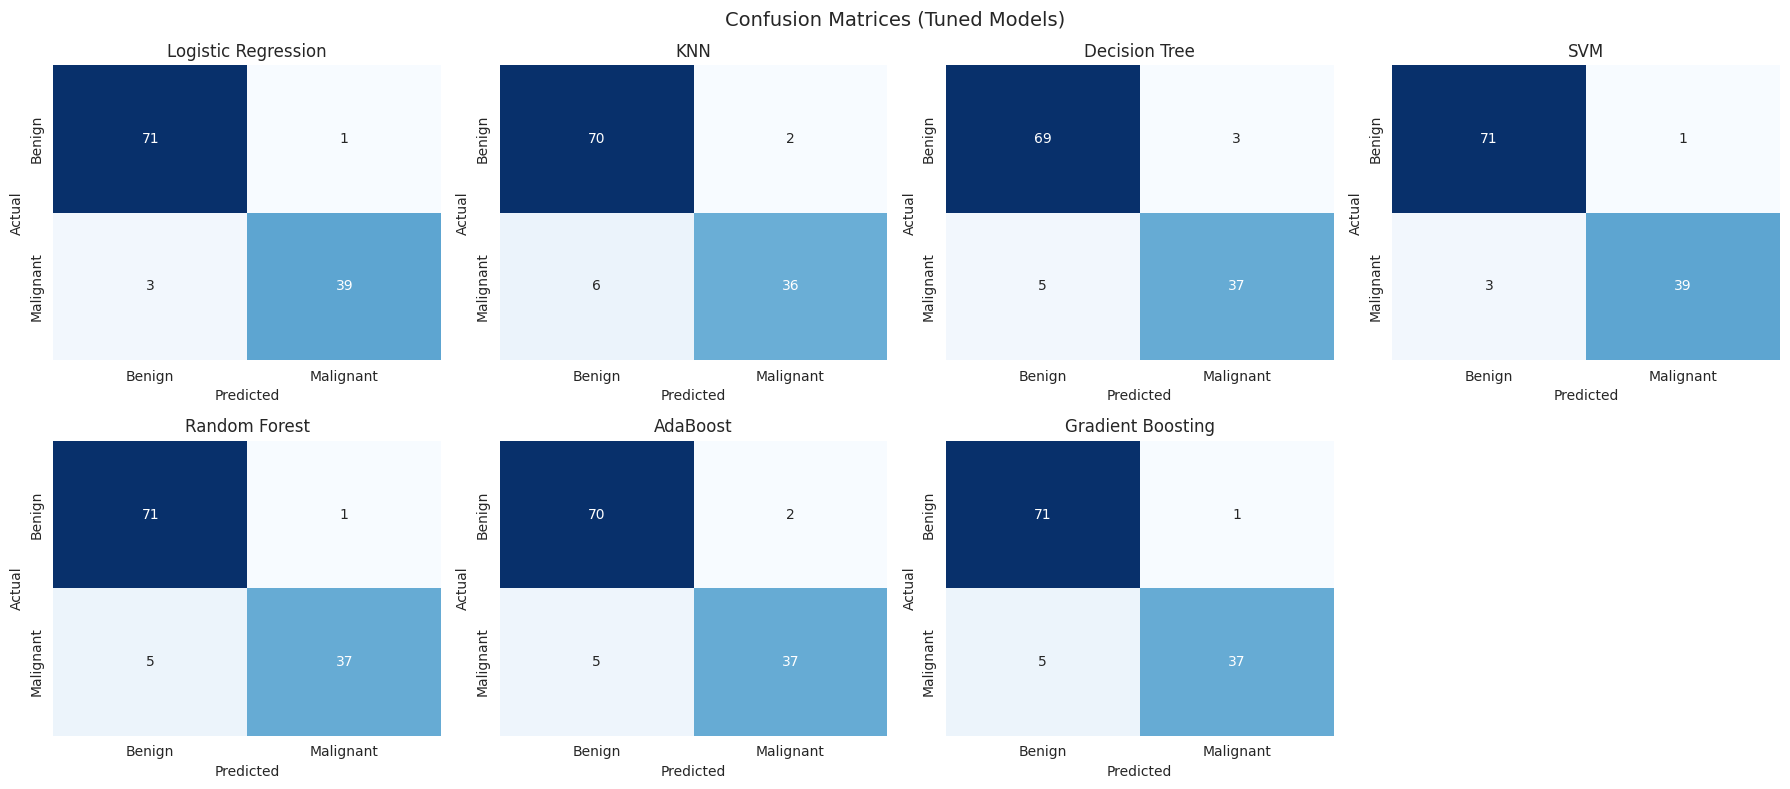

<Figure size 640x480 with 0 Axes>


===== TUNED MODEL COMPARISON =====
                     Accuracy  Precision  Recall  F1-Score     AUC
Logistic Regression    0.9649     0.9750  0.9286    0.9512  0.9947
KNN                    0.9298     0.9474  0.8571    0.9000  0.9889
Decision Tree          0.9298     0.9250  0.8810    0.9024  0.9196
SVM                    0.9649     0.9750  0.9286    0.9512  0.9950
Random Forest          0.9474     0.9737  0.8810    0.9250  0.9848
AdaBoost               0.9386     0.9487  0.8810    0.9136  0.9924
Gradient Boosting      0.9474     0.9737  0.8810    0.9250  0.9838


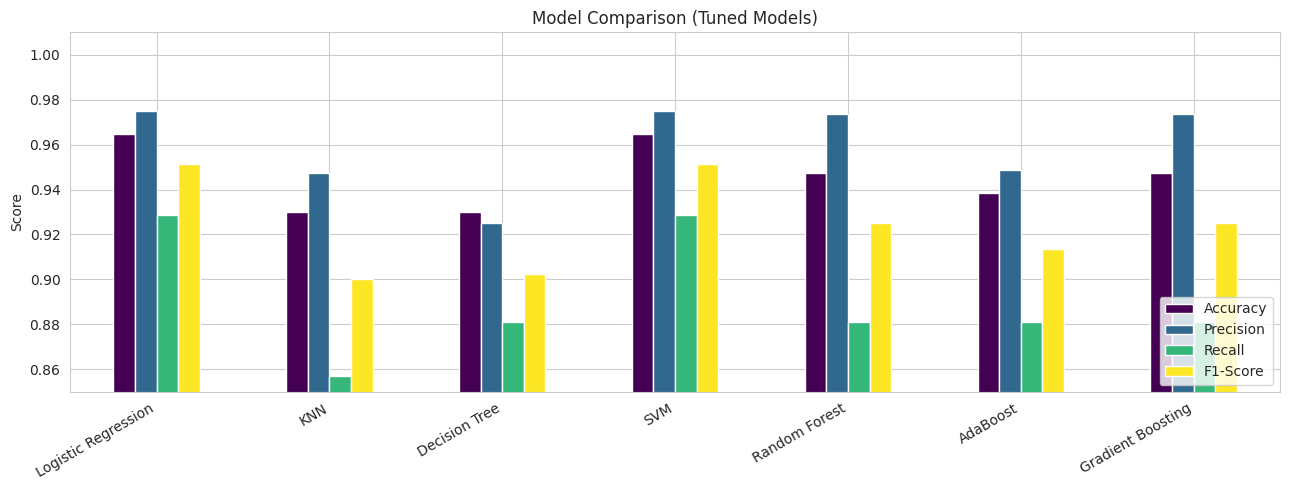

In [32]:
results_tuned = evaluate(tuned_models, "(Tuned Models)")
print("\n===== TUNED MODEL COMPARISON =====")
print(results_tuned.round(4))

results_tuned.drop(columns="AUC").plot(kind="bar", figsize=(13, 5), ylim=(0.85, 1.01), colormap="viridis")
plt.title("Model Comparison (Tuned Models)")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
save_show("12_model_comparison_tuned")

In [33]:
compare = pd.DataFrame({
    "Base Accuracy":  results_base["Accuracy"],
    "Tuned Accuracy": results_tuned["Accuracy"],
    "Base F1":        results_base["F1-Score"],
    "Tuned F1":       results_tuned["F1-Score"],
}).round(4)
print("\n===== ACCURACY & F1-SCORE (Base vs Tuned) =====")
print(compare.sort_values("Tuned F1", ascending=False))


===== ACCURACY & F1-SCORE (Base vs Tuned) =====
                     Base Accuracy  Tuned Accuracy  Base F1  Tuned F1
Logistic Regression         0.9474          0.9649   0.9250    0.9512
SVM                         0.9474          0.9649   0.9268    0.9512
Random Forest               0.9474          0.9474   0.9250    0.9250
Gradient Boosting           0.9474          0.9474   0.9231    0.9250
AdaBoost                    0.9298          0.9386   0.9000    0.9136
Decision Tree               0.9298          0.9298   0.9024    0.9024
KNN                         0.9649          0.9298   0.9512    0.9000


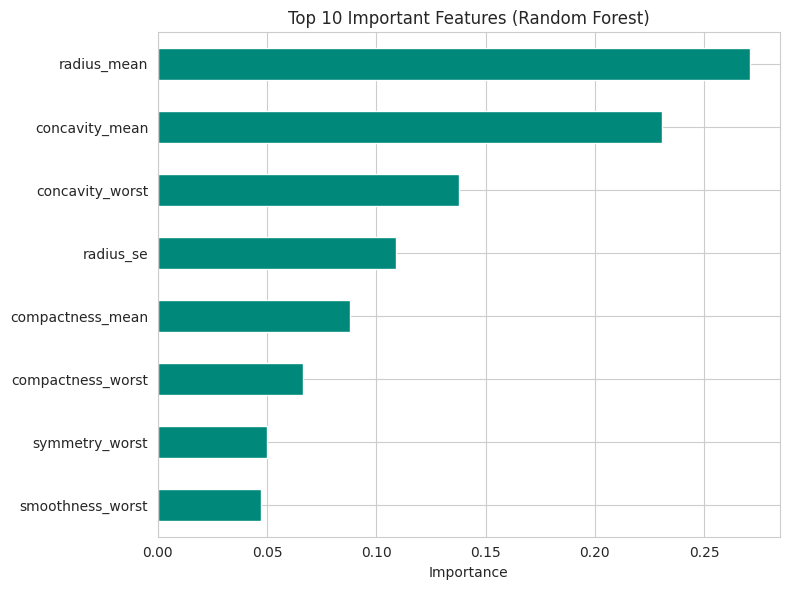


Top 10 features (Random Forest):
 radius_mean          0.2712
concavity_mean       0.2306
concavity_worst      0.1376
radius_se            0.1090
compactness_mean     0.0881
compactness_worst    0.0663
symmetry_worst       0.0499
smoothness_worst     0.0472
dtype: float64


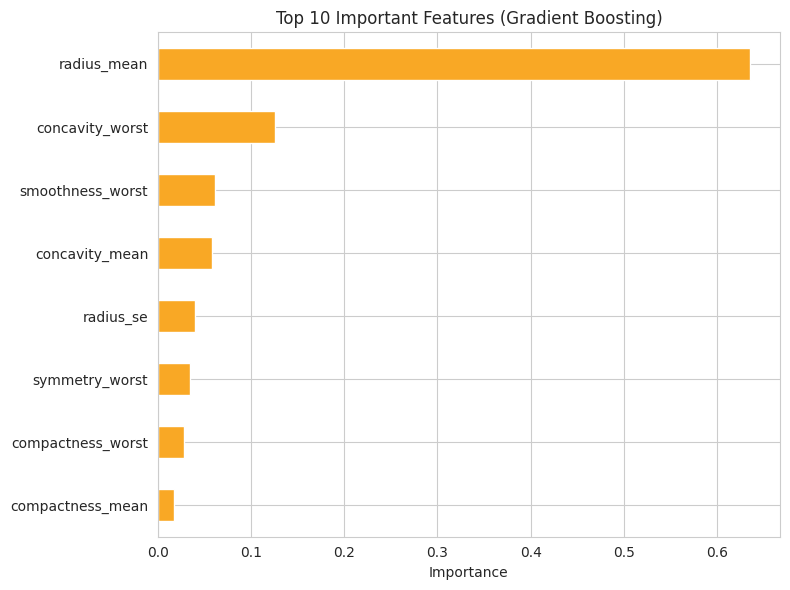

In [34]:
rf = tuned_models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=selected_features).sort_values(ascending=False)[:10]
plt.figure(figsize=(8, 6))
importance[::-1].plot(kind="barh", color="#00897B")
plt.title("Top 10 Important Features (Random Forest)")
plt.xlabel("Importance")
save_show("13_feature_importance")
print("\nTop 10 features (Random Forest):\n", importance.round(4))

gb = tuned_models["Gradient Boosting"]
importance_gb = pd.Series(gb.feature_importances_, index=selected_features).sort_values(ascending=False)[:10]
plt.figure(figsize=(8, 6))
importance_gb[::-1].plot(kind="barh", color="#F9A825")
plt.title("Top 10 Important Features (Gradient Boosting)")
plt.xlabel("Importance")
save_show("13b_feature_importance_gb")

In [35]:
results_base.round(4).to_csv("results_base_models.csv")
results_tuned.round(4).to_csv("results_tuned_models.csv")

# Best model = highest Recall (most important for cancer), ties broken by F1
best_name = results_tuned.sort_values(["Recall", "F1-Score"], ascending=False).index[0]
best_model = tuned_models[best_name]
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")          # all original features
joblib.dump(selected_features, "selected_features.pkl")  # features the model uses
print(f"\nBest model: {best_name}  -> saved as best_model.pkl")


Best model: Logistic Regression  -> saved as best_model.pkl


In [36]:
model = joblib.load("best_model.pkl")
sc = joblib.load("scaler.pkl")
all_features = joblib.load("feature_names.pkl")
sel_features = joblib.load("selected_features.pkl")
sel_idx = [all_features.index(f) for f in sel_features]

sample = X_test.iloc[[0]]                       # one patient from test data
sample_s = sc.transform(sample)[:, sel_idx]     # scale all, then keep selected features
pred = model.predict(sample_s)[0]
prob = model.predict_proba(sample_s)[0][1]
print("Prediction:", "Malignant" if pred == 1 else "Benign")
print(f"Probability of malignant: {prob*100:.2f}%")
print("Actual     :", "Malignant" if y_test.iloc[0] == 1 else "Benign")

Prediction: Benign
Probability of malignant: 2.63%
Actual     : Benign


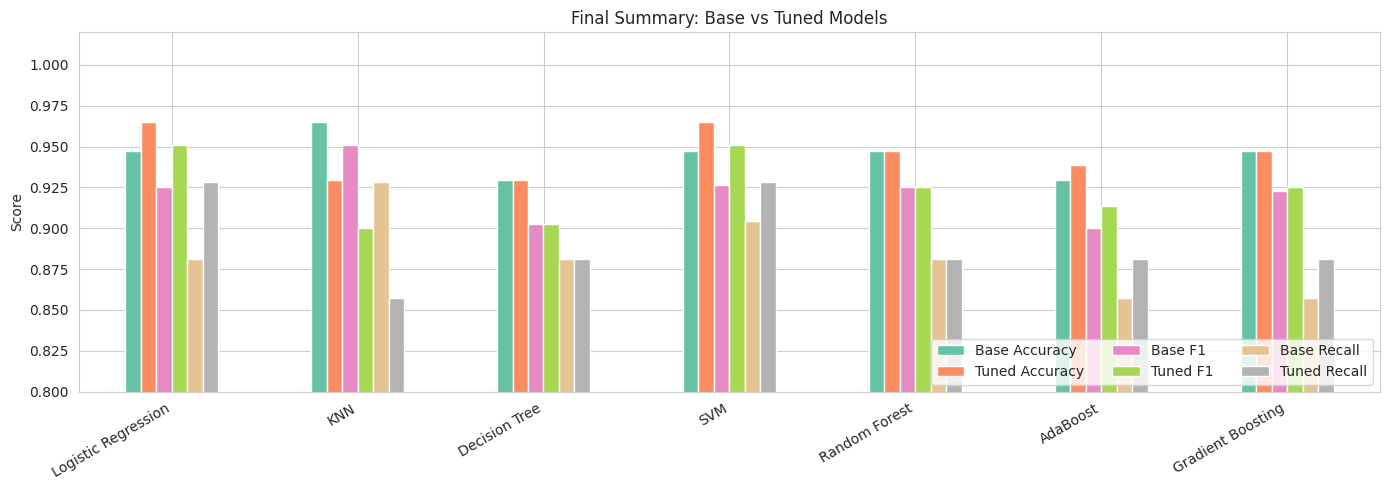

FINAL CONCLUSION

1. 7 supervised algorithms (Logistic Regression, KNN, Decision Tree, SVM, Random Forest, AdaBoost, Gradient Boosting)
   were trained on the Wisconsin Diagnostic Breast Cancer dataset (569 samples,
   reduced from 30 to 8 features by feature selection) to classify tumors
   as benign or malignant.
 
2. After scaling, 5-fold cross-validation and GridSearchCV tuning, the best
   model was LOGISTIC REGRESSION with:
      Accuracy  = 96.49%
      Precision = 97.50%
      Recall    = 92.86%
      F1-score  = 95.12%
      AUC       = 0.9947
 
3. Out of 42 malignant cases in the test set, the model correctly detected
   39 and missed 3. It raised 1 false alarm(s).
   Recall was chosen as the key metric because missing a cancer case is
   more dangerous than a false alarm.
 
4. Most important features (Random Forest): radius_mean, concavity_mean, concavity_worst.
   Most important features (Gradient Boosting): radius_mean, concavity_worst, smoothness_worst.
   Selected featur

In [37]:
final = results_tuned.copy()
best_name = final.sort_values(["Recall", "F1-Score"], ascending=False).index[0]
best = final.loc[best_name]

# Missed cancer cases (false negatives) for the best model
cm = confusion_matrix(y_test, best_model.predict(X_test_s))
tn, fp, fn, tp = cm.ravel()

# Final summary graph: base vs tuned
summary = pd.DataFrame({
    "Base Accuracy": results_base["Accuracy"], "Tuned Accuracy": results_tuned["Accuracy"],
    "Base F1": results_base["F1-Score"], "Tuned F1": results_tuned["F1-Score"],
    "Base Recall": results_base["Recall"], "Tuned Recall": results_tuned["Recall"],
})
summary.plot(kind="bar", figsize=(14, 5), ylim=(0.8, 1.02), colormap="Set2")
plt.title("Final Summary: Base vs Tuned Models")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right", ncol=3)
save_show("14_final_summary")

print("=" * 70)
print("FINAL CONCLUSION")
print("=" * 70)
print(f"""
1. {len(models)} supervised algorithms ({', '.join(models.keys())})
   were trained on the Wisconsin Diagnostic Breast Cancer dataset ({df.shape[0]} samples,
   reduced from {df.shape[1]-1} to {len(selected_features)} features by feature selection) to classify tumors
   as benign or malignant.

2. After scaling, 5-fold cross-validation and GridSearchCV tuning, the best
   model was {best_name.upper()} with:
      Accuracy  = {best['Accuracy']*100:.2f}%
      Precision = {best['Precision']*100:.2f}%
      Recall    = {best['Recall']*100:.2f}%
      F1-score  = {best['F1-Score']*100:.2f}%
      AUC       = {best['AUC']:.4f}

3. Out of {tp + fn} malignant cases in the test set, the model correctly detected
   {tp} and missed {fn}. It raised {fp} false alarm(s).
   Recall was chosen as the key metric because missing a cancer case is
   more dangerous than a false alarm.

4. Most important features (Random Forest): {', '.join(importance.index[:3])}.
   Most important features (Gradient Boosting): {', '.join(importance_gb.index[:3])}.
   Selected features: {', '.join(selected_features)}.
   Cells with larger size and more irregular shape are more likely malignant.
""")